# Mapping county health need and care indicators

This notebook is descriptive, not predictive. The first axis is the PLACES-based `NeedScore`. For a cautious quality-related comparison, the second axis is a **readmission-based effectiveness proxy**: counties with lower CMS-reported acute readmission rates score higher. Readmissions are only one imperfect indicator, not a complete measure of effectiveness.

ER visits and Medicare spending are shown separately as utilization/resource-use context. Low ER use or spending is not automatically better, and this analysis does not measure healthcare efficiency or establish causes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
county_need = pd.read_csv(PROJECT_ROOT / "data/processed/county_need_2024.csv")
cms24 = pd.read_csv(PROJECT_ROOT / "data/processed/cms24_county_small.csv")

In [2]:
county_need["CountyFIPS"] = (
    county_need["CountyFIPS"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
cms24["BENE_GEO_CD"] = (
    cms24["BENE_GEO_CD"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

analysis_df = county_need.merge(
    cms24,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner",
    validate="one_to_one",
)

metric_columns = [
    "NeedScore",
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
for column in metric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

print(f"Merged counties: {len(analysis_df):,}")

Merged counties: 3,142


## Prepare the primary comparison and sensitivity scores

The primary vertical axis will use the readmission measure alone, reversed and standardized. This avoids combining care quality, utilization, and cost into one label. We will also compare that priority group with two alternate summaries: a mean of readmission/ER indicators, and a three-indicator score that additionally treats lower spending as favorable. These alternatives are sensitivity checks, not validated efficiency scores. Using complete cases for all components makes the comparisons use the same counties.

In [3]:
care_indicators = [
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
score_df = analysis_df[
    ["StateAbbr", "CountyName", "CountyFIPS", "total_population", "NeedScore"]
    + care_indicators
].dropna().copy()

for column in care_indicators:
    score_df[f"{column}_z"] = (
        score_df[column] - score_df[column].mean()
    ) / score_df[column].std()

score_df["ReadmissionEffectivenessProxy"] = -score_df["ACUTE_HOSP_READMSN_PCT_z"]
score_df["ReadmissionErSummary"] = -score_df[
    ["ACUTE_HOSP_READMSN_PCT_z", "ER_VISITS_PER_1000_BENES_z"]
].mean(axis=1)
score_df["ThreeIndicatorSummary"] = -score_df[
    [f"{column}_z" for column in care_indicators]
].mean(axis=1)

score_df[[
    "NeedScore", "ReadmissionEffectivenessProxy",
    "ReadmissionErSummary", "ThreeIndicatorSummary",
]].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,2996.0,1.360233e+00,2.065968,-4.492298,-0.075007,1.162341,2.866045,9.314433
ReadmissionEffectivenessProxy,2996.0,7.328361e-16,1.000000,-6.968722,-0.608394,-0.015593,0.613235,5.555426
ReadmissionErSummary,2996.0,6.640586e-17,0.817728,-4.961072,-0.512760,0.013324,0.490646,4.753985
ThreeIndicatorSummary,2996.0,1.849878e-16,0.747930,-4.610358,-0.441991,0.019198,0.472570,4.344204


## Visualize need versus the readmission proxy

The quadrant with above-median need and a below-median readmission proxy contains counties with higher need and higher readmission rates. Call these **priority candidates for investigation**, not proven underperformers. A high readmission rate can have multiple causes.

In [4]:
need_cutoff = score_df["NeedScore"].median()
performance_cutoff = score_df["ReadmissionEffectivenessProxy"].median()

def assign_quadrant(row):
    high_need = row["NeedScore"] >= need_cutoff
    higher_readmission_proxy = row["ReadmissionEffectivenessProxy"] >= performance_cutoff
    if high_need and not higher_readmission_proxy:
        return "High need / higher readmissions"
    if high_need and higher_readmission_proxy:
        return "High need / lower readmissions"
    if not high_need and higher_readmission_proxy:
        return "Lower need / lower readmissions"
    return "Lower need / higher readmissions"

score_df["Quadrant"] = score_df.apply(assign_quadrant, axis=1)
score_df["Priority"] = score_df["Quadrant"].eq("High need / higher readmissions")
score_df["Quadrant"].value_counts().to_frame("count")

,count
Quadrant,
Lower need / lower readmissions,849
High need / higher readmissions,848
High need / lower readmissions,650
Lower need / higher readmissions,649


## Check whether priority counties depend on the score definition

Use the same complete-case counties and the same median need cutoff for each version. The readmission-only proxy is the primary definition. The other versions add ER visits and then spending; comparing their overlap shows how sensitive the flagged group is to assumptions about what counts as better care.

In [5]:
score_definitions = {
    "Readmissions only (primary)": "ReadmissionEffectivenessProxy",
    "Readmissions + ER visits": "ReadmissionErSummary",
    "Readmissions + ER + spending": "ThreeIndicatorSummary",
}
primary_priority = score_df["Priority"]
sensitivity_rows = []

for label, column in score_definitions.items():
    is_priority = (
        score_df["NeedScore"].ge(need_cutoff)
        & score_df[column].lt(score_df[column].median())
    )
    intersection = (is_priority & primary_priority).sum()
    union = (is_priority | primary_priority).sum()
    sensitivity_rows.append({
        "Score definition": label,
        "Priority counties": int(is_priority.sum()),
        "Same as primary": int(intersection),
        "Overlap with primary (%)": round(100 * intersection / primary_priority.sum(), 1),
        "Jaccard similarity": round(intersection / union, 3) if union else 1.0,
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table

,Score definition,Priority counties,Same as primary,Overlap with primary (%),Jaccard similarity
0,Readmissions only (primary),848,848,100.0,1.000
1,Readmissions + ER visits,947,763,90.0,0.739
2,Readmissions + ER + spending,970,732,86.3,0.674


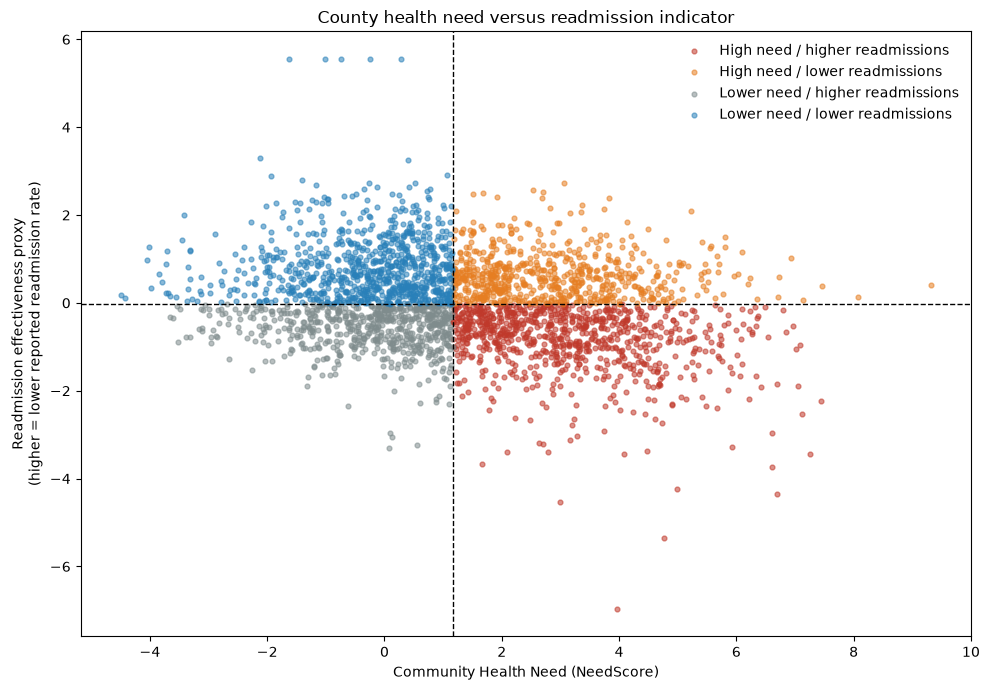

In [6]:
colors = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / lower readmissions": "#2980b9",
    "Lower need / higher readmissions": "#7f8c8d",
}

fig, ax = plt.subplots(figsize=(10, 7))
for quadrant, group in score_df.groupby("Quadrant"):
    ax.scatter(
        group["NeedScore"],
        group["ReadmissionEffectivenessProxy"],
        s=12,
        alpha=0.55,
        label=quadrant,
        color=colors[quadrant],
    )
ax.axvline(need_cutoff, color="black", linestyle="--", linewidth=1)
ax.axhline(performance_cutoff, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Community Health Need (NeedScore)")
ax.set_ylabel("Readmission effectiveness proxy\n(higher = lower reported readmission rate)")
ax.set_title("County health need versus readmission indicator")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

In [7]:
priority_counties = (
    score_df[score_df["Priority"]]
    .sort_values(["NeedScore", "ReadmissionEffectivenessProxy"], ascending=[False, True])
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "ReadmissionEffectivenessProxy", *care_indicators,
    ]]
)
priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,NeedScore,ReadmissionEffectivenessProxy,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,TOT_MDCR_STDZD_PYMT_PC
2413,SD,Oglala Lakota,46102,7.440376,-2.239415,601.8237,0.2380,17629.81
3093,WV,Mingo,54059,7.257157,-3.451218,860.5372,0.2750,11085.57
2587,TX,Dimmit,48127,7.117166,-2.537453,890.9774,0.2471,16632.19
1067,KY,Magoffin,21153,7.080552,-0.955559,664.9810,0.1988,11434.53
1543,MS,Humphreys,28053,7.050507,-1.888975,658.9674,0.2273,14724.98
150,AR,Phillips,05107,7.017548,-1.040713,500.0000,0.2014,11653.10
61,AL,Greene,01063,6.961679,-0.536341,543.7616,0.1860,11800.14
1146,LA,Madison,22065,6.841615,-0.664071,902.4123,0.1899,18872.13
35,AL,Bullock,01011,6.791085,-0.153149,482.6923,0.1743,12279.03
1058,KY,Lee,21129,6.698802,-4.351883,668.8453,0.3025,12957.29


## Compare individual indicators for priority candidates

The priority label is based only on NeedScore and the readmission proxy. Compare ER visits and spending separately: they provide context but do not define effectiveness.

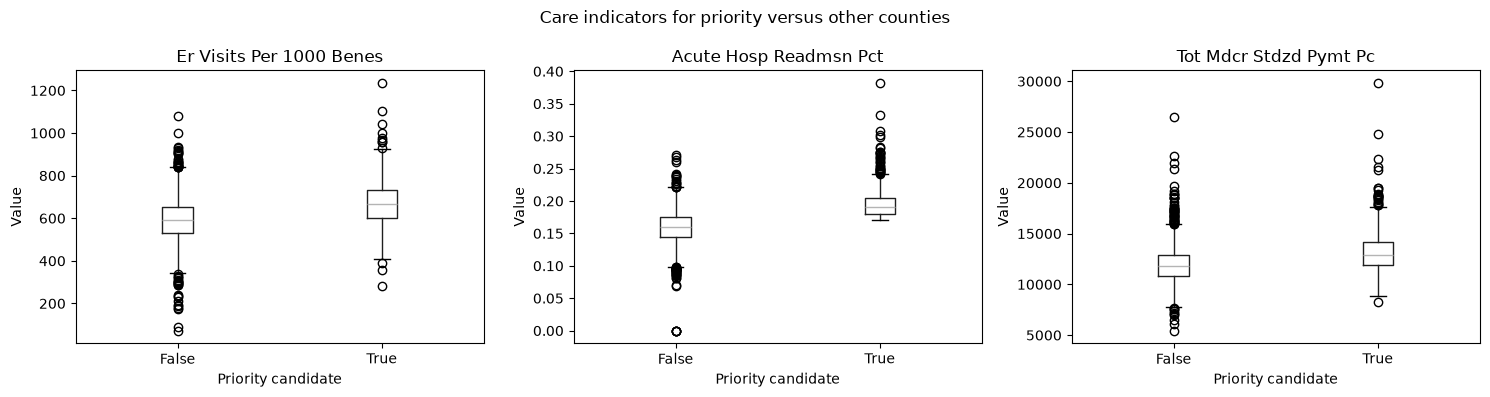

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, care_indicators):
    score_df.boxplot(column=column, by="Priority", ax=ax, grid=False)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Priority candidate")
    ax.set_ylabel("Value")
fig.suptitle("Care indicators for priority versus other counties")
plt.tight_layout()
plt.show()

## Map need, readmissions, ER visits, and spending

These county choropleths keep each measure separate so the map does not conceal tradeoffs in a composite. The notebook downloads the official [2024 Census TIGER/Line county boundaries](https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip) and caches them under `data/raw/` (ignored by Git). Install the small shapefile reader once with `python -m pip install -r requirements-mapping.txt`. The map separates the contiguous U.S., Alaska, and Hawaii; territories are excluded. Colors are clipped to each measure's 2nd and 98th percentiles to make county patterns easier to see; use the raw data/table for extremes.

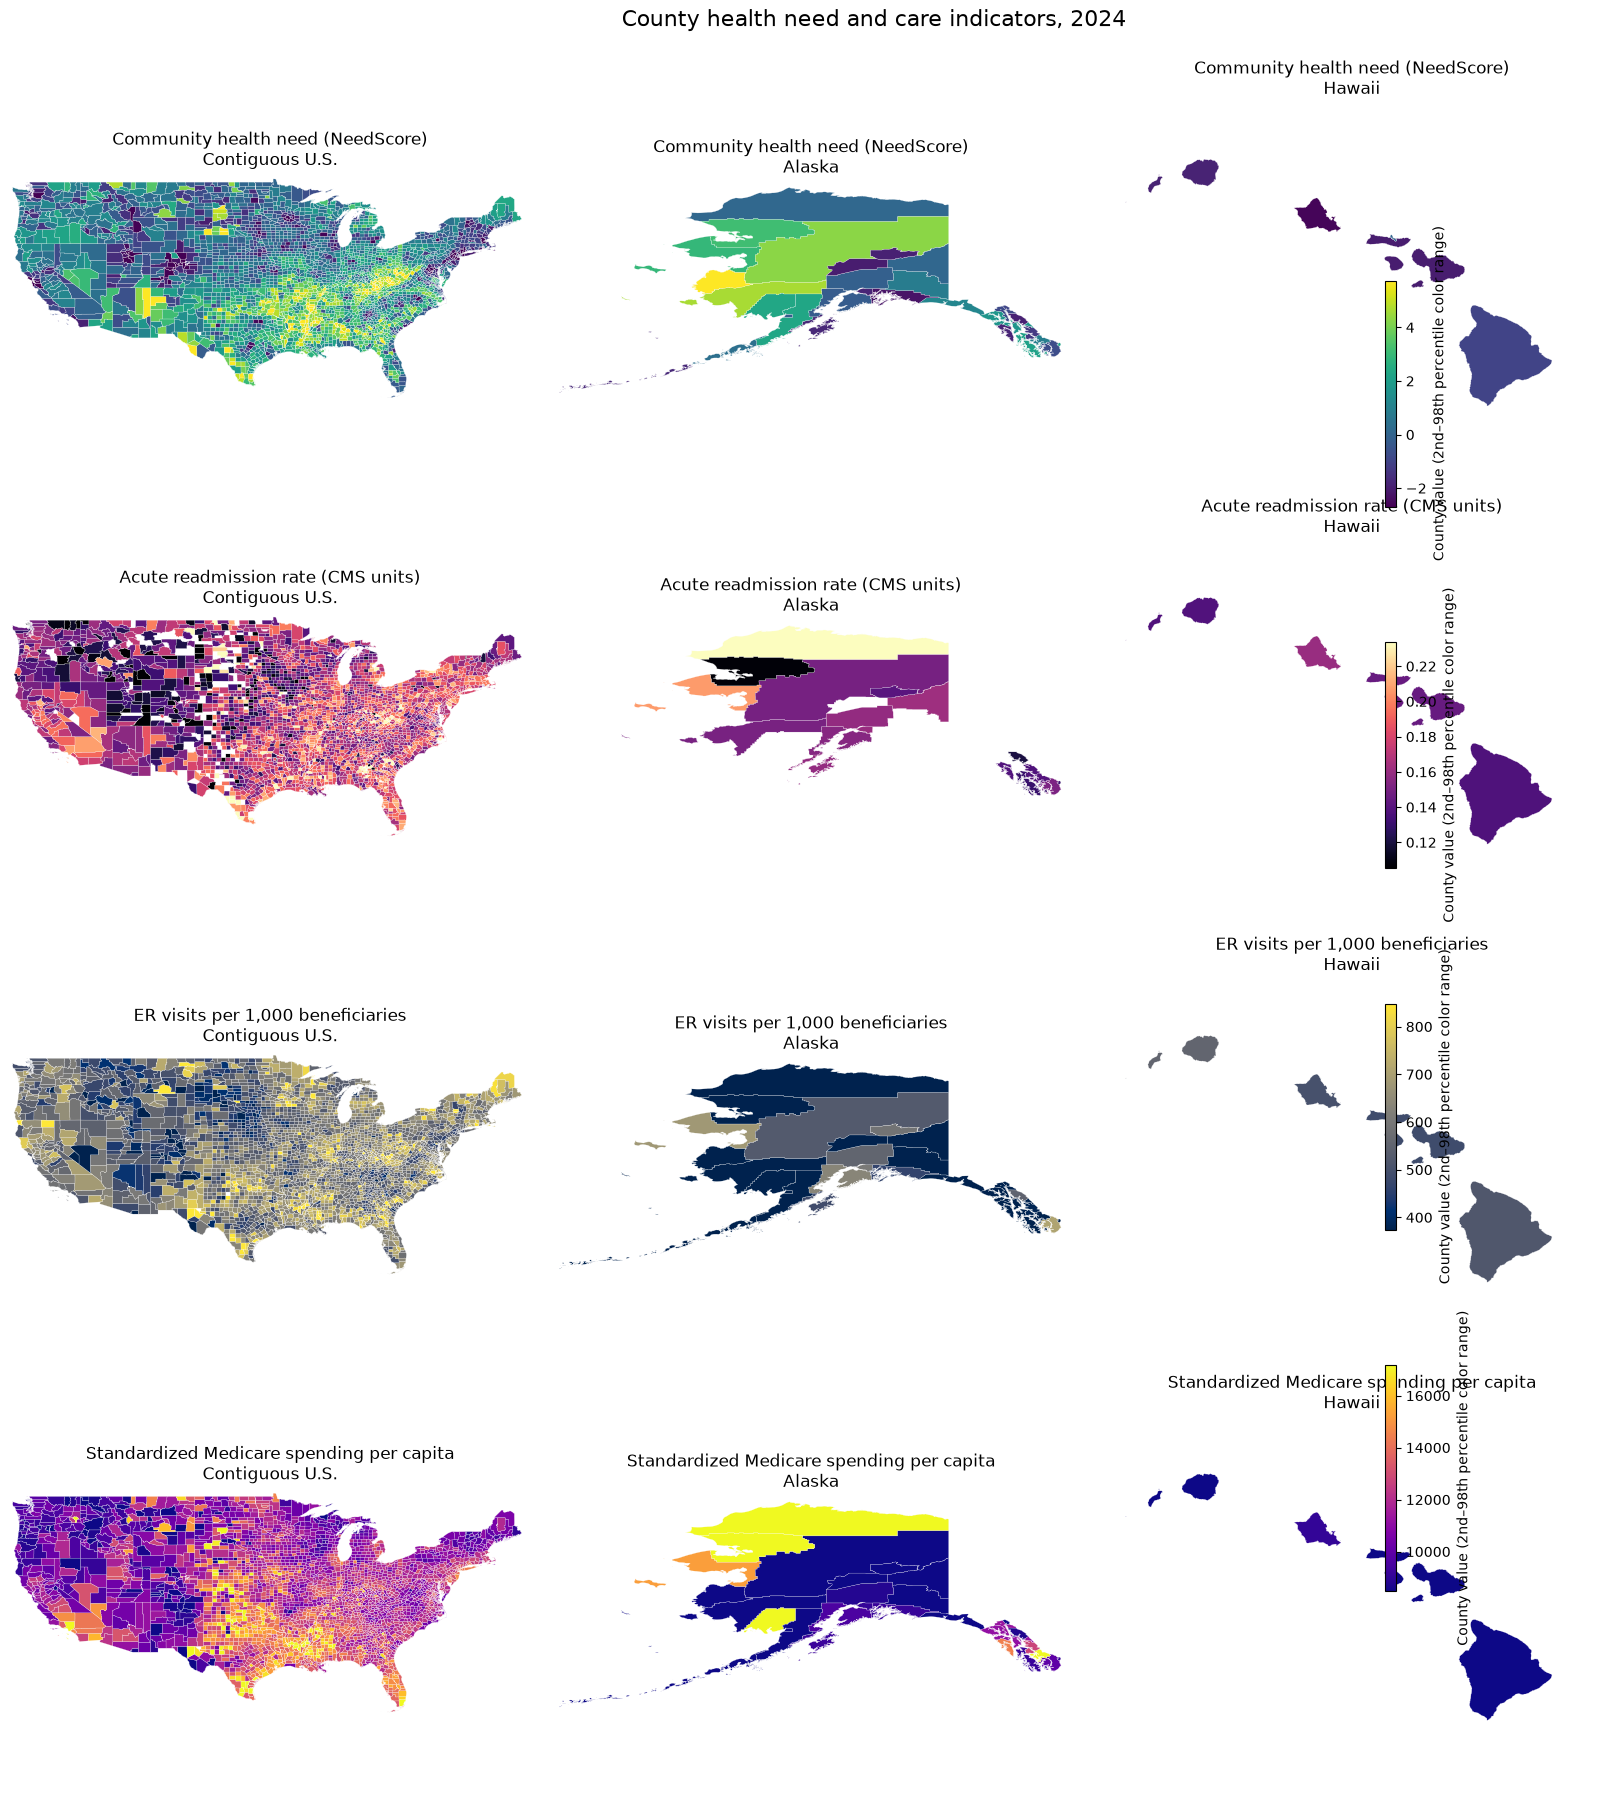

County polygons with data by region:
Contiguous U.S.: 3,107
Alaska: 30
Hawaii: 5


In [9]:
import ssl
import zipfile
from pathlib import Path
from urllib.request import urlopen

import certifi
import numpy as np
import shapefile
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon as MapPolygon

raw_dir = PROJECT_ROOT / "data/raw"
raw_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = raw_dir / "cb_2024_us_county_500k.zip"
shape_path = raw_dir / "cb_2024_us_county_500k.shp"
if not boundary_zip.exists():
    boundary_url = (
        "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
        "cb_2024_us_county_500k.zip"
    )
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(boundary_url, context=context, timeout=60) as response:
        boundary_zip.write_bytes(response.read())

if not shape_path.exists():
    with zipfile.ZipFile(boundary_zip) as archive:
        members = {Path(name).suffix.lower(): name for name in archive.namelist()}
        for extension in (".shp", ".shx", ".dbf"):
            shape_member = members.get(extension)
            if shape_member is None:
                raise FileNotFoundError(f"Missing {extension} in Census boundary archive")
            (raw_dir / f"cb_2024_us_county_500k{extension}").write_bytes(
                archive.read(shape_member)
            )

county_by_fips = analysis_df.set_index("CountyFIPS")
region_state_codes = {
    "Contiguous U.S.": None,
    "Alaska": {"02"},
    "Hawaii": {"15"},
}
territory_codes = {"60", "66", "69", "72", "78"}
region_polygons = {region: [] for region in region_state_codes}

with shapefile.Reader(str(shape_path), encoding="utf-8") as county_shapes:
    field_names = [field[0] for field in county_shapes.fields[1:]]
    for shape_record in county_shapes.iterShapeRecords():
        record = dict(zip(field_names, shape_record.record))
        state_code = str(record["STATEFP"]).zfill(2)
        county_fips = str(record["GEOID"]).zfill(5)
        if county_fips not in county_by_fips.index:
            continue
        if state_code in territory_codes:
            continue

        if state_code == "02":
            region = "Alaska"
        elif state_code == "15":
            region = "Hawaii"
        else:
            region = "Contiguous U.S."

        points = shape_record.shape.points
        part_starts = list(shape_record.shape.parts) + [len(points)]
        for start, end in zip(part_starts, part_starts[1:]):
            region_polygons[region].append((points[start:end], county_fips))

map_metrics = [
    ("NeedScore", "Community health need (NeedScore)", "viridis"),
    ("ACUTE_HOSP_READMSN_PCT", "Acute readmission rate (CMS units)", "magma"),
    ("ER_VISITS_PER_1000_BENES", "ER visits per 1,000 beneficiaries", "cividis"),
    ("TOT_MDCR_STDZD_PYMT_PC", "Standardized Medicare spending per capita", "plasma"),
]
region_limits = {
    "Contiguous U.S.": (-125, -66, 24, 50),
    "Alaska": (-180, -129, 51, 72),
    "Hawaii": (-161, -154, 18, 23),
}

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for row, (column, title, cmap) in enumerate(map_metrics):
    values = county_by_fips[column].dropna()
    lower, upper = values.quantile([0.02, 0.98])
    norm = Normalize(vmin=lower, vmax=upper, clip=True)
    for col_index, (region, limits) in enumerate(region_limits.items()):
        ax = axes[row, col_index]
        patches = []
        patch_values = []
        for exterior, county_fips in region_polygons[region]:
            county_value = county_by_fips.at[county_fips, column]
            if pd.notna(county_value):
                patches.append(MapPolygon(exterior, closed=True))
                patch_values.append(county_value)

        collection = PatchCollection(
            patches, cmap=cmap, norm=norm,
            edgecolor="white", linewidth=0.15,
        )
        collection.set_array(np.asarray(patch_values))
        ax.add_collection(collection)
        west, east, south, north = limits
        ax.set_xlim(west, east)
        ax.set_ylim(south, north)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{title}\n{region}")
        ax.set_axis_off()

    colorbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=axes[row, :].tolist(),
        shrink=0.75,
        pad=0.02,
    )
    colorbar.set_label("County value (2nd–98th percentile color range)")

plt.suptitle("County health need and care indicators, 2024", y=1.01, fontsize=16)
fig.subplots_adjust(left=0.02, right=0.91, bottom=0.02, top=0.96, wspace=0.04, hspace=0.16)
plt.show()

print("County polygons with data by region:")
for region, polygons in region_polygons.items():
    print(f"{region}: {len({fips for _, fips in polygons}):,}")

In [10]:
score_df.to_csv(
    PROJECT_ROOT / "data/processed/county_need_readmission_quadrants_2024.csv",
    index=False,
)